# 02. Modeling

Alur: split stratified, perbandingan ukuran model, training (dijalankan dari terminal), lalu evaluasi dan analisis error. Setiap hasil diikuti sel interpretasi.

Catatan: angka pada interpretasi berasal dari run ResNet18, input 160 piksel, 8 epoch. Perbarui jika model dilatih ulang.

In [5]:
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image as IPImage, display

from scripts.config import Config, CLASS_NAMES, NUM_CLASSES
from scripts.dataset import make_splits, make_loaders
from scripts.model import build_model, count_parameters
from scripts.evaluate import collect_val_predictions, top_confusions, plot_history, plot_confusion_matrix
from scripts.utils import get_device, set_seed
from sklearn.metrics import confusion_matrix, classification_report

cfg = Config()
set_seed(cfg.seed)
device = get_device()
labels = pd.read_csv(cfg.train_csv)["label"].to_numpy()
train_idx, val_idx = make_splits(labels, cfg.val_ratio, cfg.seed)
print(device, len(train_idx), len(val_idx))

cpu 27202 4801


Seluruh komputasi berjalan di CPU. Data latih dibagi menjadi 27.202 gambar untuk training dan 4.801 untuk validasi (85 banding 15) dengan seed tetap, sehingga eksperimen dapat diulang dan setiap model dibandingkan pada validasi yang sama.

## 1. Split validasi
Stratified 85/15 dengan seed tetap. Kedua subset harus memiliki proporsi kelas yang sama.

In [6]:
print(pd.DataFrame({"train": np.bincount(labels[train_idx], minlength=16) / len(train_idx),
                    "val": np.bincount(labels[val_idx], minlength=16) / len(val_idx)}).round(4).T)

           0       1       2       3       4       5       6       7       8   \
train  0.0629  0.0626  0.0629  0.0632  0.0626  0.0633  0.0619  0.0616  0.0623   
val    0.0629  0.0627  0.0629  0.0631  0.0627  0.0633  0.0619  0.0617  0.0623   

           9       10      11      12      13      14      15  
train  0.0616  0.0622  0.0609  0.0634  0.0643  0.0625  0.0618  
val    0.0617  0.0623  0.0608  0.0633  0.0642  0.0625  0.0619  


Proporsi tiap kelas pada train dan validasi hampir identik (selisih terbesar sekitar 0,0001, dengan nilai di kisaran 0,061 sampai 0,064 atau sekitar 1/16). Stratifikasi bekerja, jadi akurasi validasi tidak bias oleh komposisi kelas. Setiap kelas memiliki sekitar 300 sampel validasi, sehingga recall per kelas memiliki ketidakpastian sekitar 4 poin persentase (selang 95 persen untuk recall 0,8). Selisih per kelas yang lebih kecil dari itu tidak boleh dibaca sebagai perbedaan nyata.

## 2. Ukuran model

In [7]:
for name in ["resnet18", "mobilenet_v3_small", "mobilenet_v3_large"]:
    total, _ = count_parameters(build_model(name, pretrained=False))
    print(f"{name:20s} {total / 1e6:.2f} juta parameter")

resnet18             11.18 juta parameter
mobilenet_v3_small   1.53 juta parameter
mobilenet_v3_large   4.22 juta parameter


ResNet18 memiliki 11,18 juta parameter, sekitar 2,6 kali MobileNetV3 large (4,22 juta) dan 7 kali MobileNetV3 small (1,53 juta). Jumlah parameter bukan satu-satunya penentu waktu di CPU, tetapi menjadi indikator kapasitas dan risiko overfitting. ResNet18 dipilih sebagai model utama karena waktu per epoch (sekitar 22 menit) masih sangat memungkinkan untuk digunakan, dan MobileNetV3 large menjadi pembanding yang lebih ringan.

## 3. Menjalankan training

Training dapat dijalankan dari notebook ini (ubah `RUN_TRAINING` menjadi `True`) atau dari terminal dengan perintah yang setara:

```bash
python -m scripts.train --model resnet18 --epochs 8 --freeze-epochs 1 --threads 8
```
Di CPU, training memakan sekitar 2,8 jam, jadi pada notebook ini sakelarnya dibiarkan `False` dan hasil yang tersimpan (checkpoint dan riwayat) yang dipakai pada bagian berikutnya. Untuk proses panjang, terminal lebih aman karena tidak terputus jika kernel berhenti.

In [8]:
RUN_TRAINING = False   # True untuk melatih ulang (di CPU, menimpa checkpoint dengan nama sama)

if RUN_TRAINING:
    from scripts.train import fit
    set_seed(cfg.seed)
    torch.set_num_threads(8)
    model = build_model("resnet18", pretrained=True).to(device)
    train_loader, val_loader = make_loaders(cfg, train_idx, val_idx, labels)
    meta_base = {"image_size": int(cfg.image_size), "seed": int(cfg.seed),
                 "val_ratio": float(cfg.val_ratio), "val_idx": [int(i) for i in val_idx]}
    history = fit(model, train_loader, val_loader, cfg, "resnet18", meta_base,
                  epochs=8, freeze_epochs=1, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=3, device=device)
else:
    print("Training dilewati; memakai checkpoint dan riwayat yang sudah tersimpan.")

Training dilewati; memakai checkpoint dan riwayat yang sudah tersimpan.


In [9]:
log_path = cfg.figures_dir.parent / "train_resnet18.log"
print(log_path.read_text(encoding="utf-8", errors="ignore")[-3000:] if log_path.exists()
      else "Log training tidak ditemukan.")

  t r a i n   0 . 9 3 4 0 / 0 . 8 8 2 3     v a l   1 . 0 9 7 2 / 0 . 8 2 0 2     1 3 1 1 s 
 
     c h e c k p o i n t   d i s i m p a n   ( v a l   a c c   0 . 8 2 0 2 ) 
 
     b a t c h   5 0 / 4 2 6     l o s s   0 . 8 5 4 9     a c c   0 . 9 2 0 3     1 4 6 s 
 
     b a t c h   1 0 0 / 4 2 6     l o s s   0 . 8 4 9 0     a c c   0 . 9 2 1 6     2 9 3 s 
 
     b a t c h   1 5 0 / 4 2 6     l o s s   0 . 8 4 4 1     a c c   0 . 9 2 2 1     4 3 8 s 
 
     b a t c h   2 0 0 / 4 2 6     l o s s   0 . 8 3 8 3     a c c   0 . 9 2 4 1     5 8 2 s 
 
     b a t c h   2 5 0 / 4 2 6     l o s s   0 . 8 3 8 2     a c c   0 . 9 2 4 1     7 2 7 s 
 
     b a t c h   3 0 0 / 4 2 6     l o s s   0 . 8 3 7 2     a c c   0 . 9 2 4 2     8 7 4 s 
 
     b a t c h   3 5 0 / 4 2 6     l o s s   0 . 8 3 8 8     a c c   0 . 9 2 3 1     1 0 1 8 s 
 
     b a t c h   4 0 0 / 4 2 6     l o s s   0 . 8 4 0 1     a c c   0 . 9 2 2 3     1 1 6 5 s 
 
 E p o c h   6 / 8     t r a i n   0 . 8 3 9 1 / 0 . 9 

## 4. Kurva training

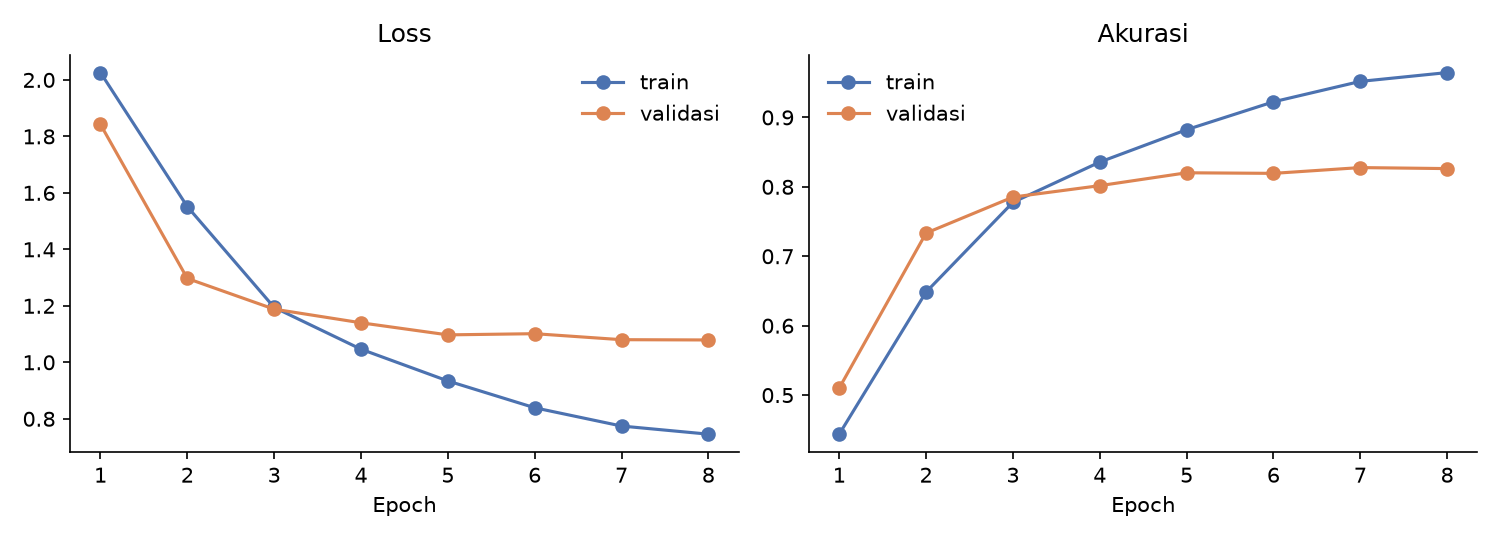

   train_loss  train_acc  val_loss  val_acc  epoch_seconds
0      2.0260     0.4437    1.8424   0.5101       787.1603
1      1.5514     0.6484    1.2969   0.7334      1457.9316
2      1.1944     0.7776    1.1882   0.7853      1387.9965
3      1.0464     0.8357    1.1400   0.8017      1313.4635
4      0.9340     0.8823    1.0972   0.8202      1310.5776
5      0.8391     0.9225    1.1014   0.8194      1310.9245
6      0.7744     0.9519    1.0801   0.8277      1308.2574
7      0.7456     0.9646    1.0792   0.8263      1327.3378


In [10]:
CKPT = cfg.checkpoint_dir / "resnet18_160_best.pt"      # ganti sesuai eksperimen terbaik
hist = json.loads((cfg.checkpoint_dir / "resnet18_160_history.json").read_text())
plot_history(hist, cfg.figures_dir / "history_resnet18_160.png")
display(IPImage(filename=str(cfg.figures_dir / "history_resnet18_160.png")))
print(pd.DataFrame(hist).round(4))

* Epoch 1 melatih head saja dengan backbone beku dan menghasilkan akurasi validasi 0,510. Begitu seluruh jaringan dibuka pada epoch 2, akurasi validasi melonjak ke 0,733 (naik sekitar 22 poin), yang menunjukkan fitur ImageNet saja tidak cukup untuk dokumen dan fine-tuning penuh sangat diperlukan. 
* Akurasi validasi naik cepat sampai epoch 4 (0,802), lalu mendatar di kisaran 0,82 sampai 0,83 pada epoch 5 sampai 8 (0,820, 0,819, 0,828, 0,826). Puncaknya 0,828 pada epoch 7, tetapi selisih antar epoch tersebut masih dalam noise (galat standar sekitar 0,5 poin), sehingga tidak bisa dikatakan terus membaik. Akurasi train terus naik sampai 0,965, jadi pada akhir training ada kesenjangan sekitar 14 poin: model overfitting. 
* Loss validasi berhenti turun sekitar epoch 5 (1,097 menjadi 1,079) sementara loss train terus turun. Loss validasi lebih besar daripada loss train sebagian karena label smoothing 0,1 menaikkan batas bawah loss, jadi nilainya tidak sebanding dengan cross-entropy biasa.
* Menambah epoch tidak akan membantu; perbaikan harus dari regularisasi, data, atau resolusi. Waktu: epoch 1 sekitar 13 menit dan epoch 2 sampai 8 sekitar 22 sampai 24 menit, total sekitar 2,8 jam.

## 5. Evaluasi pada validasi

Akurasi validasi: 0.8277


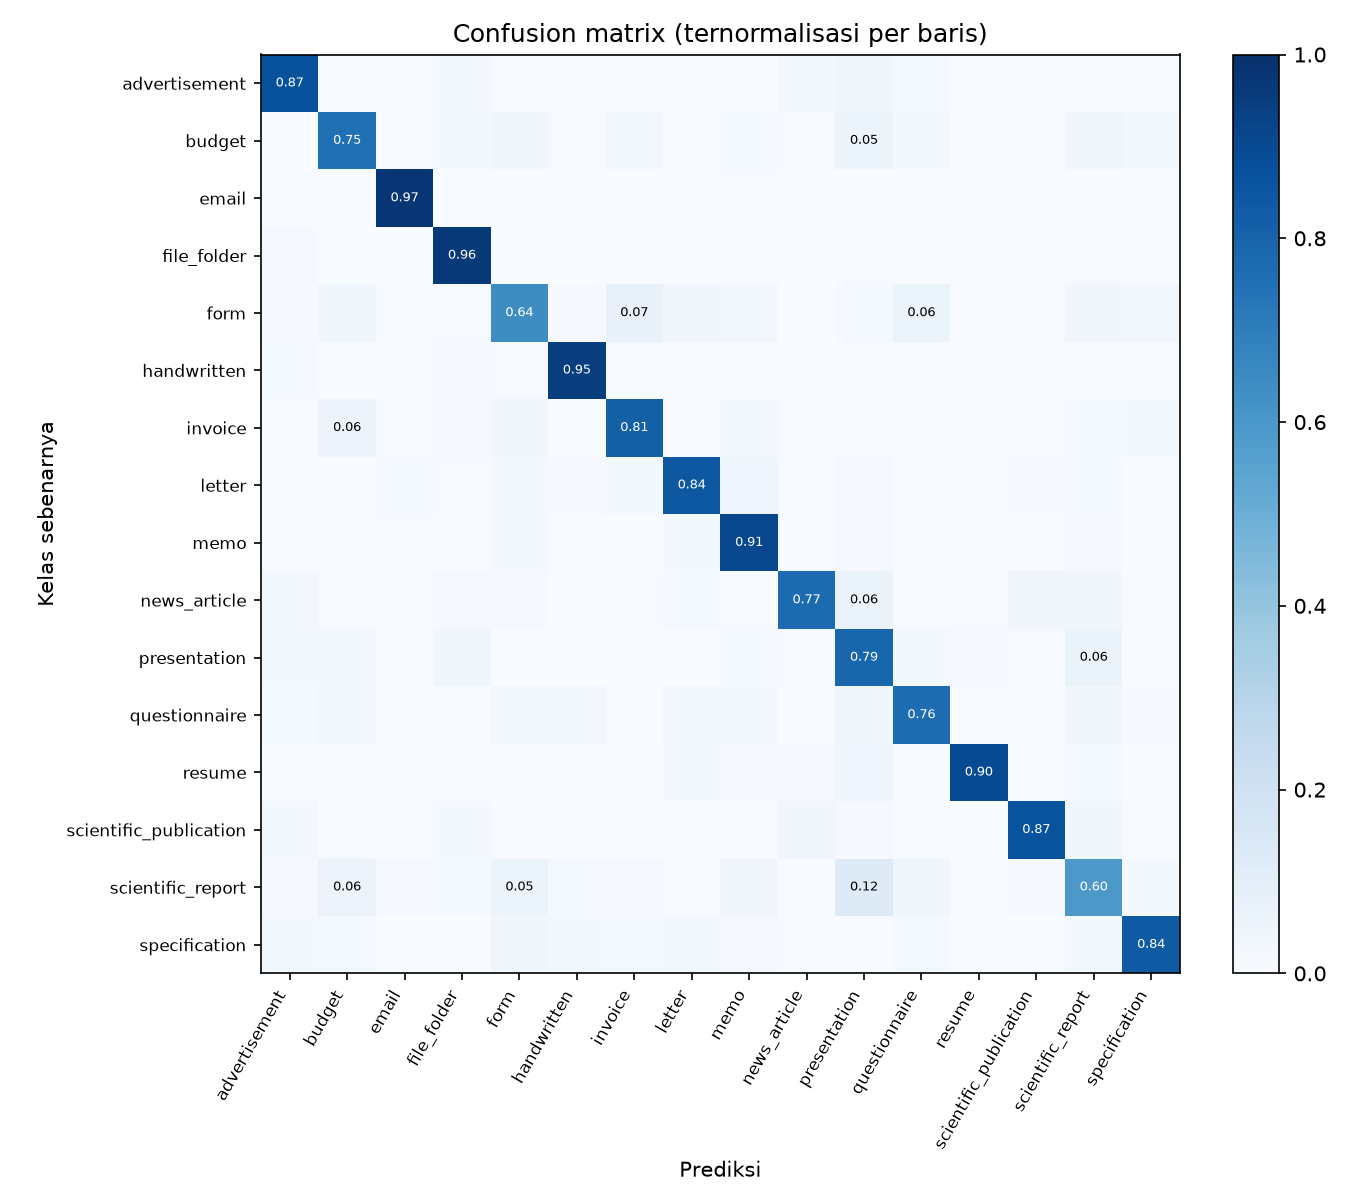

                        precision    recall  f1-score   support

         advertisement      0.859     0.871     0.865       302
                budget      0.756     0.751     0.753       301
                 email      0.945     0.974     0.959       302
           file_folder      0.856     0.960     0.905       303
                  form      0.724     0.645     0.682       301
           handwritten      0.909     0.947     0.928       304
               invoice      0.823     0.815     0.819       297
                letter      0.833     0.845     0.839       296
                  memo      0.814     0.910     0.859       299
          news_article      0.880     0.770     0.822       296
          presentation      0.657     0.789     0.717       299
         questionnaire      0.802     0.764     0.782       292
                resume      0.955     0.898     0.925       304
scientific_publication      0.918     0.867     0.891       308
     scientific_report      0.651     0

In [11]:
preds, targets, vidx, meta = collect_val_predictions(CKPT, cfg, device)
names = [CLASS_NAMES[i] for i in range(NUM_CLASSES)]
cm = confusion_matrix(targets, preds, labels=range(NUM_CLASSES))
print("Akurasi validasi:", (preds == targets).mean().round(4))
plot_confusion_matrix(cm, names, cfg.figures_dir / "confusion_matrix_notebook.png")
display(IPImage(filename=str(cfg.figures_dir / "confusion_matrix_notebook.png")))
print(classification_report(targets, preds, target_names=names, digits=3))

Akurasi validasi 0,828 pada 4.801 sampel, sekitar 13 kali garis dasar tebakan acak (0,0625). Galat standarnya sekitar 0,5 poin, jadi selisih antar model di bawah sekitar 1 poin belum bisa dianggap nyata. Macro average (0,827) hampir sama dengan akurasi, sesuai kelas yang seimbang.

Kelas terkuat berdasarkan F1: email 0,959, handwritten 0,928, resume 0,925, dan file_folder 0,905; kelas ini punya pola visual yang sangat khas. Kelas terlemah: scientific_report 0,623 (precision dan recall sama-sama rendah, 0,651 dan 0,597), form 0,682 (recall hanya 0,645), presentation 0,717, dan budget 0,753.

Presentation menunjukkan pola tidak seimbang: recall 0,789 tetapi precision hanya 0,657, artinya banyak dokumen kelas lain diprediksi sebagai presentation sehingga ia berperan sebagai kelas penampung. Sebaliknya news_article memiliki precision 0,880 dengan recall 0,770: ketika model memilih kelas ini biasanya benar, tetapi banyak yang terlewat. Dengan ketidakpastian per kelas sekitar 4 poin, urutan kelas di tengah (F1 sekitar 0,82 sampai 0,86) tidak bisa dibedakan secara meyakinkan. Pada confusion matrix, diagonal sama dengan recall di tabel ini dan sel di luar diagonal yang bernilai minimal 0,05 diberi angka.

In [12]:
pd.DataFrame(top_confusions(cm, names, k=10))

,true,pred,count,rate
0,scientific_report,presentation,37,0.123333
1,form,invoice,22,0.073090
2,news_article,presentation,19,0.064189
3,presentation,scientific_report,19,0.063545
4,form,questionnaire,18,0.059801
5,scientific_report,budget,17,0.056667
6,invoice,budget,17,0.057239
7,budget,presentation,16,0.053156
8,scientific_report,form,16,0.053333
9,resume,presentation,13,0.042763


Kesalahan terbesar adalah scientific_report diprediksi presentation sebanyak 37 kasus (12,3 persen dari kelasnya). Pasangan berikutnya: form menjadi invoice (22) dan menjadi questionnaire (18), news_article menjadi presentation (19), presentation menjadi scientific_report (19, jadi tertukar dua arah), serta scientific_report dan invoice menjadi budget (masing-masing 17).

Ada tiga pola. Pertama, presentation menjadi tujuan salah pada empat dari sepuluh pasangan teratas (dari scientific_report, news_article, budget, resume). Kedua, kesalahan berkumpul pada kelompok dokumen berbentuk tabel dan kotak: form, invoice, budget, questionnaire, scientific_report. Ketiga, hipotesis di notebook 01 bahwa letter, memo, dan email akan paling sering tertukar tidak didukung data: ketiganya justru memiliki F1 0,84 sampai 0,96 dan tidak muncul di daftar ini. Pasangan scientific_publication dan scientific_report juga tidak masuk sepuluh besar.

Dugaan penyebabnya (belum terbukti): pada 160 piksel teks tidak terbaca, sehingga kelas yang pembedanya adalah isi (misalnya laporan ilmiah versus slide) mudah tertukar dengan kelas yang tata letaknya mirip. Sel 6 memeriksa 8 contoh acak, dan pasangan kesalahan terbesar. Pasangan terkecil di daftar hanya 13 kasus, jadi kesalahan cukup tersebar dan tidak didominasi satu pasangan di luar yang pertama.

## 6. Contoh gambar yang salah prediksi

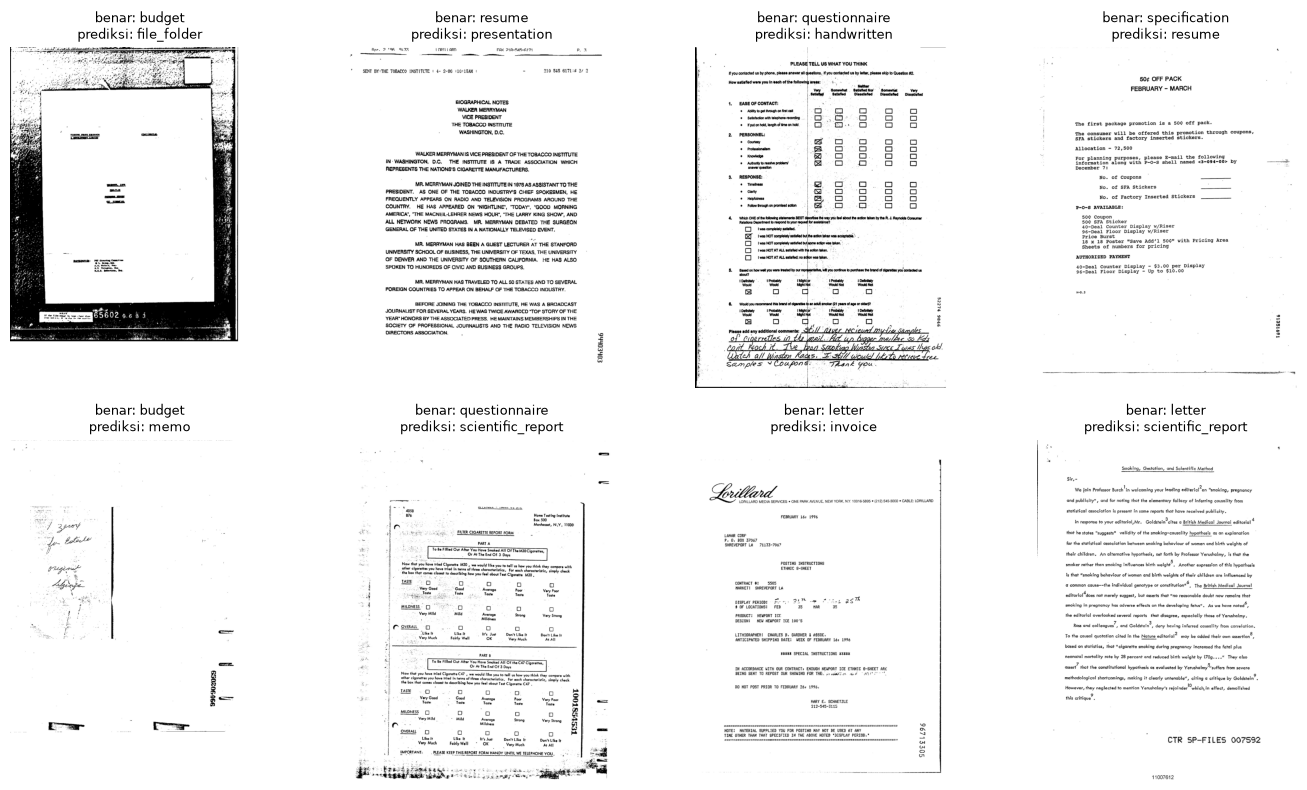

In [13]:
from PIL import Image
train_df = pd.read_csv(cfg.train_csv)
wrong = np.where(preds != targets)[0]
rng = np.random.default_rng(0)
pick = rng.choice(wrong, size=min(8, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, k in zip(axes.ravel(), pick):
    row = train_df.iloc[vidx[k]]
    with Image.open(cfg.data_dir / row["filename"]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(f"benar: {names[targets[k]]}\nprediksi: {names[preds[k]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
fig.savefig(cfg.figures_dir / "misclassified_examples.png", dpi=120)
plt.show()

**Interpretasi:** 

Sel ini menampilkan 8 contoh acak dari sekitar 830 kesalahan validasi (4.801 sampel dikurangi yang diprediksi benar). Pengamatan dari 8 contoh, yang merupakan sampel kecil dan hanya menunjukkan pola yang tampak, bukan proporsi:

1. Tidak ada halaman yang terotasi 90 derajat atau miring pada 8 contoh ini, jadi orientasi bukan penjelasan yang terlihat di sampel ini.
2. Beberapa kesalahan melibatkan dokumen yang memang bercampur ciri dua kelas: questionnaire dengan komentar tulisan tangan diprediksi handwritten, formulir laporan rokok (questionnaire) diprediksi scientific_report, letter yang berisi blok data terstruktur diprediksi invoice, dan letter yang tampak seperti halaman makalah dengan catatan kaki diprediksi scientific_report. Label pada kasus ini wajar tetapi ambigu, sehingga sebagian error adalah batas atas yang sulit dicapai model.
3. Dua contoh menunjukkan masalah kualitas scan: budget yang diprediksi file_folder berupa halaman gelap berbingkai hitam, dan budget yang diprediksi memo hampir kosong dengan coretan samar.
4. Tidak ada satu pun dari 8 contoh yang berkelas benar scientific_report, padahal itu sumber kesalahan terbesar. Karena itu sel ini belum menguji dugaan tentang pasangan scientific_report dan presentation.

### Contoh pada pasangan kesalahan terbesar

scientific_report -> presentation: 37 kasus


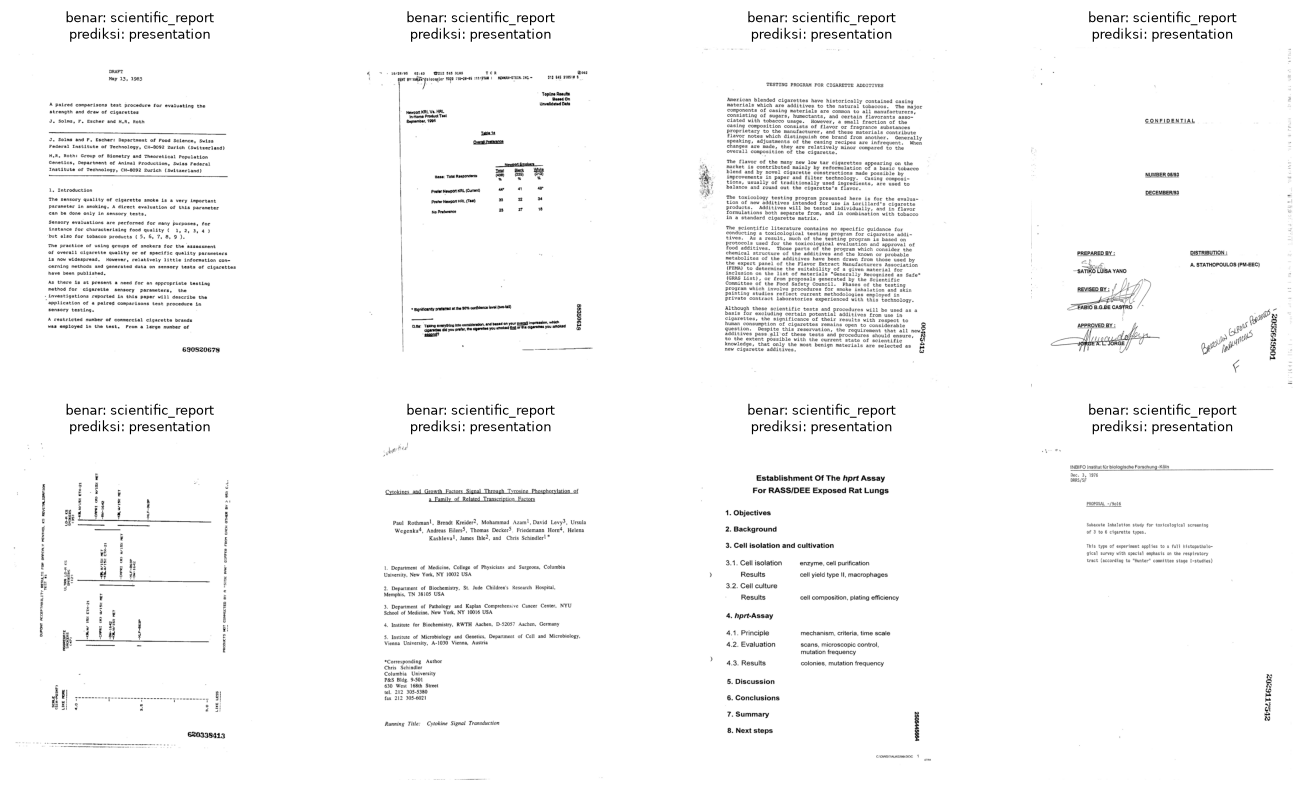

In [14]:
top = top_confusions(cm, names, k=1)[0]           # pasangan kesalahan terbanyak
t_lab, p_lab = names.index(top["true"]), names.index(top["pred"])
pair = np.where((targets == t_lab) & (preds == p_lab))[0]
print(f"{top['true']} -> {top['pred']}: {len(pair)} kasus")
pick = np.random.default_rng(0).choice(pair, size=min(8, len(pair)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, k in zip(axes.ravel(), pick):
    row = train_df.iloc[vidx[k]]
    with Image.open(cfg.data_dir / row["filename"]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(f"benar: {names[targets[k]]}\nprediksi: {names[preds[k]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
fig.savefig(cfg.figures_dir / "top_confusion_examples.png", dpi=120)
plt.show()

**Interpretasi:** 

 Sel ini menampilkan 8 dari 37 kasus scientific_report yang diprediksi presentation, yaitu kesalahan terbesar. Karena sampelnya kecil, hasilnya adalah pola yang tampak, bukan proporsi.

Hanya satu dari delapan contoh yang terotasi 90 derajat (halaman grafik), jadi orientasi bukan penyebab utama. Lima contoh berupa halaman yang jarang teks dan tidak berkolom padat: halaman tabel hasil dengan banyak ruang putih, halaman sampul bertanda tangan, halaman judul makalah berisi penulis dan afiliasi, halaman proposal yang hampir kosong, dan halaman daftar poin bernomor yang memang menyerupai slide agenda. Pada 160 piksel halaman seperti ini sulit dibedakan dari slide, karena yang tersisa hanya blok pendek dan banyak ruang kosong. Dua contoh lain berupa halaman teks padat yang tampak seperti laporan biasa, sehingga kesalahan pada keduanya tidak dijelaskan oleh tata letak yang jarang dan mungkin terkait keterbatasan resolusi atau kemampuan model.

Temuan ini menunjukkan bahwa kelas scientific_report heterogen (sampul, tabel, grafik, halaman judul, dan halaman teks), sehingga recall-nya rendah (0,597). Dugaan kemiripan tata letak dengan slide didukung sebagian (5 dari 8 contoh), sedangkan dugaan rotasi sebagai penyebab dominan tidak didukung (1 dari 8). Implikasinya, menaikkan resolusi mungkin membantu pada halaman teks tetapi kecil kemungkinannya membantu pada halaman sampul atau halaman hampir kosong yang secara visual ambigu; fitur teks (OCR) lebih berpotensi membantu, namun ini hipotesis yang belum diuji.